# 气象因素与城市电力负荷分析

本 notebook 独立读取 `data/题4_城市电力负荷.csv`，依次绘制 **Pearson 相关性热力图、温度分箱负荷曲线、风速双峰分布图**。代码和图表输出均保存在本 notebook，不生成其他绘图文件。

在 Jupyter 中选择具有 `pandas`、`numpy`、`matplotlib`、`scipy` 的 Python 内核，然后从上到下运行全部单元格。若缺少依赖，可在当前内核中运行 `%pip install pandas numpy matplotlib scipy`，安装后重启内核。

分析采用原始 10 分钟观测值；相关性和分箱均值只反映描述性关联，不能直接解释为气象因素的因果作用。

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from scipy.stats import gaussian_kde
from IPython.display import display

%matplotlib inline

# 优先选用已安装的中文字体，兼容 Windows / macOS / Linux。
font_candidates = ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC',
                   'Source Han Sans SC', 'PingFang SC', 'WenQuanYi Micro Hei']
installed_fonts = {font.name for font in font_manager.fontManager.ttflist}
chinese_font = next((name for name in font_candidates if name in installed_fonts), None)
plt.rcParams.update({'font.sans-serif': [chinese_font or 'DejaVu Sans'],
                     'axes.unicode_minus': False, 'font.size': 11,
                     'figure.dpi': 120, 'axes.spines.top': False,
                     'axes.spines.right': False})
if chinese_font is None:
    print('提示：当前环境缺少中文字体，可安装微软雅黑、黑体或 Noto Sans CJK SC。')

colors = {'Z1': '#2463A6', 'Z2': '#E48A28', 'Z3': '#239B82'}
zone_labels = {'Z1': '分区 1', 'Z2': '分区 2', 'Z3': '分区 3'}
print('依赖导入完成。')

依赖导入完成。


## 1. 读取与检查数据

自动查找当前目录或上级目录中的指定 CSV，因此从项目根目录启动 Jupyter 即可。按实际列名映射字段，保留原始负荷单位 kW。非数值或无效时间会明确报错；有效的缺失数值在各项分析中按所需字段剔除，并显示样本量。

In [2]:
filename = '题4_城市电力负荷.csv'
search_roots = [Path.cwd()] + list(Path.cwd().parents)
candidates = [root / 'data' / filename for root in search_roots]
candidates += [Path.cwd() / filename]
csv_path = next((path for path in candidates if path.is_file()), None)
if csv_path is None:
    raise FileNotFoundError('未找到 data/' + filename + '，请从 City_load 项目目录启动 Jupyter。')

with csv_path.open('r', encoding='utf-8-sig') as csv_file:
    raw = pd.read_csv(csv_file)
raw.columns = [' '.join(str(name).split()) for name in raw.columns]
column_map = {
    'DateTime': 'DateTime', 'Temperature': 'T', 'Humidity': 'RH',
    'Wind Speed': 'WS', 'general diffuse flows': 'GDF', 'diffuse flows': 'DF',
    'Zone 1 Power Consumption': 'Z1', 'Zone 2 Power Consumption': 'Z2',
    'Zone 3 Power Consumption': 'Z3'
}
missing_columns = set(column_map).difference(raw.columns)
if missing_columns:
    raise ValueError('CSV 缺少必要列：' + str(sorted(missing_columns)))
df = raw[list(column_map)].rename(columns=column_map).copy()
df['DateTime'] = pd.to_datetime(df['DateTime'], format='%m/%d/%Y %H:%M', errors='raise')
if df['DateTime'].isna().any():
    raise ValueError('存在缺失时间，请检查 CSV。')
numeric_cols = ['T', 'RH', 'WS', 'GDF', 'DF', 'Z1', 'Z2', 'Z3']
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='raise')
df[numeric_cols] = df[numeric_cols].replace([np.inf, -np.inf], np.nan)
df = df.set_index('DateTime').sort_index()
if df.index.duplicated().any():
    raise ValueError('存在重复时间戳，请先确认重复记录的处理方法。')
if (df['WS'].dropna() < 0).any():
    raise ValueError('存在负风速，请检查原始数据。')
print('数据文件：', csv_path)
print('数据规模：{} 行 × {} 个数值字段'.format(*df.shape))
print('时间范围：{} 至 {}'.format(df.index.min(), df.index.max()))
print('各列缺失数量：', df.isna().sum().to_dict())
display(df.head())

数据文件： C:\Users\Lenovo\Desktop\python\City_load\data\题4_城市电力负荷.csv
数据规模：52416 行 × 8 个数值字段
时间范围：2017-01-01 00:00:00 至 2017-12-30 23:50:00
各列缺失数量： {'T': 0, 'RH': 0, 'WS': 0, 'GDF': 0, 'DF': 0, 'Z1': 0, 'Z2': 0, 'Z3': 0}


,T,RH,WS,GDF,DF,Z1,Z2,Z3
DateTime,,,,,,,,
2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
2017-01-01 00:10:00,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2017-01-01 00:20:00,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


## 2. Pearson 相关性热力图

展示五个气象指标与三个分区负荷的完整相关矩阵。色阶固定为 −1 到 1：正值代表同向线性关联，负值代表反向线性关联，接近 0 仅表示线性关联较弱。每对变量使用两列均有效的观测；下方单独列出气象与负荷的相关系数。GDF、DF 保留原始指标名，避免推断其单位。

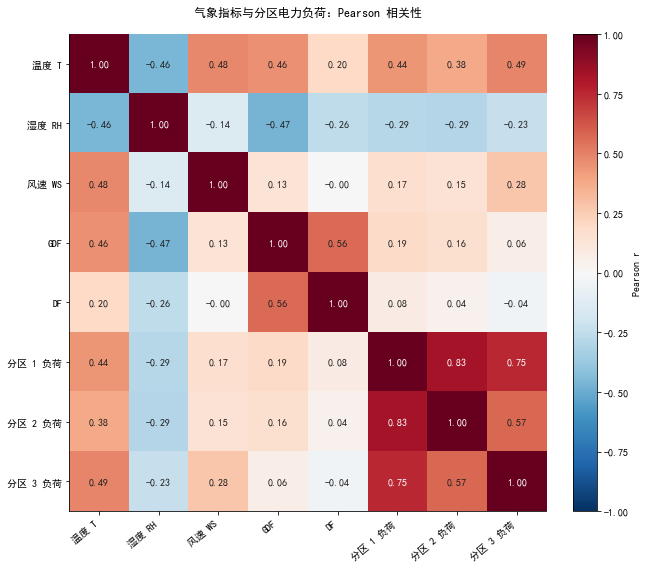

,Z1,Z2,Z3
T,0.440,0.382,0.490
RH,-0.287,-0.295,-0.233
WS,0.167,0.146,0.279
GDF,0.188,0.157,0.063
DF,0.080,0.045,-0.039


In [3]:
corr = df[numeric_cols].corr(method='pearson')
labels = ['温度 T', '湿度 RH', '风速 WS', 'GDF', 'DF', '分区 1 负荷', '分区 2 负荷', '分区 3 负荷']
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(np.arange(len(labels)))
ax.set_yticks(np.arange(len(labels)))
ax.set_xticklabels(labels, rotation=40, ha='right')
ax.set_yticklabels(labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        value = corr.iloc[i, j]
        ax.text(j, i, '{:.2f}'.format(value) if pd.notna(value) else 'NA',
                ha='center', va='center', fontsize=10,
                color='white' if abs(value) > 0.60 else '#202020')
ax.set_title('气象指标与分区电力负荷：Pearson 相关性', pad=18)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04).set_label('Pearson r')
fig.tight_layout()
plt.show()
display(corr.loc[['T', 'RH', 'WS', 'GDF', 'DF'], ['Z1', 'Z2', 'Z3']].round(3))

## 3. 温度分箱与平均负荷曲线

按 **2°C 等宽区间**分箱，区间左闭右开，横轴为区间中点。三个分区分别计算平均负荷，每个分区仅展示有效负荷样本量不少于 **100** 的温度箱；不足的箱以断线表示。下图显示温度观测数量，浅灰色表示温度样本少于 100 的区间。

分箱宽度与最低样本量可以在下方修改。曲线未控制季节、时刻、湿度等因素，连线仅辅助观察，不代表预测模型。

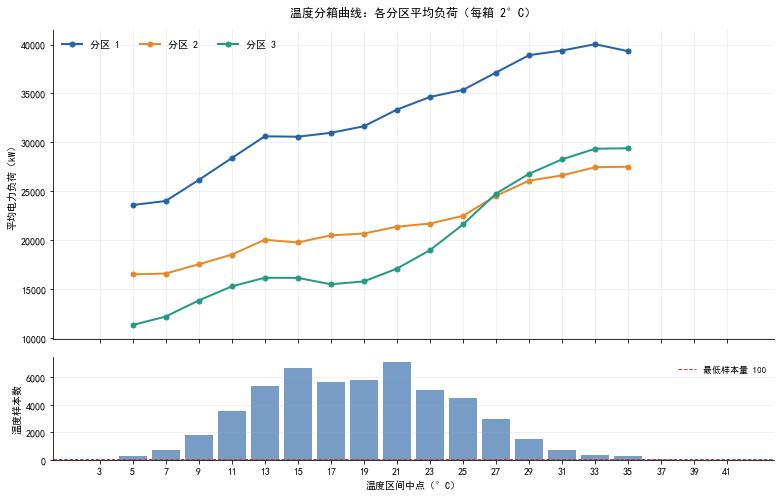

,温度样本数,分区 1均值(kW),分区 2均值(kW),分区 3均值(kW),分区 1有效样本数,分区 2有效样本数,分区 3有效样本数
温度箱,,,,,,,
"[2.0, 4.0)",22,24210.2,15028.2,13718.1,22,22,22
"[4.0, 6.0)",288,23599.5,16509.4,11326.9,288,288,288
"[6.0, 8.0)",743,24006.4,16594.4,12196.3,743,743,743
"[8.0, 10.0)",1821,26155.1,17535.8,13836.2,1821,1821,1821
"[10.0, 12.0)",3562,28392.4,18527.5,15279.5,3562,3562,3562
"[12.0, 14.0)",5329,30623.3,20046.3,16162.2,5329,5329,5329
"[14.0, 16.0)",6676,30581.5,19770.4,16149.8,6676,6676,6676
"[16.0, 18.0)",5625,30980.3,20498.7,15499.1,5625,5625,5625
"[18.0, 20.0)",5801,31647.0,20684.6,15788.9,5801,5801,5801


In [4]:
BIN_WIDTH = 2.0
MIN_SAMPLES = 100
zones = ['Z1', 'Z2', 'Z3']
temp_data = df.dropna(subset=['T']).copy()
if temp_data.empty:
    raise ValueError('没有可用于分箱的温度观测。')
lower = np.floor(temp_data['T'].min() / BIN_WIDTH) * BIN_WIDTH
upper = (np.floor(temp_data['T'].max() / BIN_WIDTH) + 1) * BIN_WIDTH
edges = np.arange(lower, upper + BIN_WIDTH * 0.5, BIN_WIDTH)
temp_data['温度箱'] = pd.cut(temp_data['T'], bins=edges, right=False)
groups = temp_data.groupby('温度箱', observed=False)
bin_mean = groups[zones].mean()
bin_count = groups[zones].count()
temp_count = groups.size()
centers = np.array([interval.mid for interval in bin_mean.index], dtype=float)
plot_mean = bin_mean.where(bin_count >= MIN_SAMPLES)

fig, (ax, ax_count) = plt.subplots(2, 1, figsize=(11, 7), sharex=True,
                                  gridspec_kw={'height_ratios': [3, 1]})
for zone in zones:
    ax.plot(centers, plot_mean[zone].values, marker='o', linewidth=2,
            markersize=5, color=colors[zone], label=zone_labels[zone])
ax.set_title('温度分箱曲线：各分区平均负荷（每箱 {:.0f}°C）'.format(BIN_WIDTH), pad=14)
ax.set_ylabel('平均电力负荷（kW）')
ax.legend(ncol=3, frameon=False)
ax.grid(alpha=0.22)
bar_colors = ['#AAB4C1' if n < MIN_SAMPLES else '#779CC6' for n in temp_count.values]
ax_count.bar(centers, temp_count.values, width=BIN_WIDTH * 0.85, color=bar_colors)
ax_count.axhline(MIN_SAMPLES, color='#B54A45', linestyle='--', linewidth=1,
                 label='最低样本量 {}'.format(MIN_SAMPLES))
ax_count.set_ylabel('温度样本数')
ax_count.set_xlabel('温度区间中点（°C）')
ax_count.set_xticks(centers)
ax_count.legend(frameon=False, fontsize=9)
ax_count.grid(axis='y', alpha=0.22)
fig.tight_layout()
plt.show()

bin_summary = bin_mean.rename(columns={zone: zone_labels[zone] + '均值(kW)' for zone in zones})
bin_summary = bin_summary.join(bin_count.rename(columns={zone: zone_labels[zone] + '有效样本数' for zone in zones}))
bin_summary.insert(0, '温度样本数', temp_count)
display(bin_summary.round(1))

## 4. 风速双峰分布

采用密度直方图叠加高斯核密度估计（KDE，Scott 默认带宽），保留全部有效风速。根据平滑曲线的局部极大值标记最多两个主要峰，候选峰至少相隔 0.5 个原始风速单位；若数据不足以形成两个峰，则如实报告。不会通过修改数据强制造峰。

CSV 表头和项目说明未明确风速单位，因此横轴使用“原始单位”。KDE 在非负边界附近存在平滑偏差，峰位为近似值，需结合直方图判断。双峰是风速自身的分布特征，并不表示负荷有双峰，也不能据此判定数据错误。

有效风速样本：52,416
风速范围：0.050 ～ 6.483
主要 KDE 峰位： [0.085, 4.916]
WS < 0.2 的样本占比：57.64%
WS >= 4.8 的样本占比：38.57%


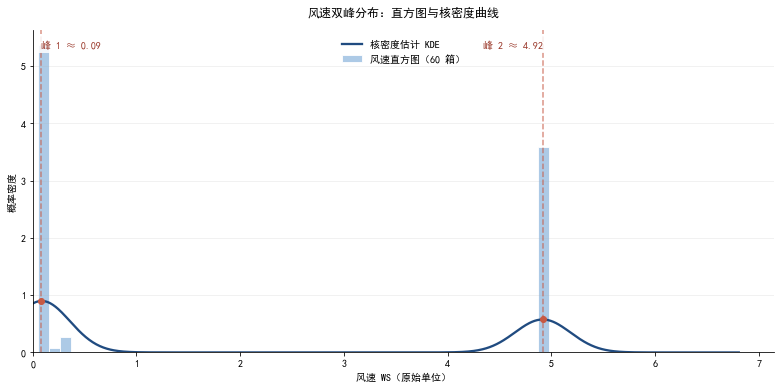

In [5]:
wind = df['WS'].dropna().values
if len(wind) < 2 or np.std(wind) == 0:
    raise ValueError('有效风速不足或风速恒定，无法估计密度。')
x_grid = np.linspace(0, max(wind.max() * 1.05, 0.1), 800)
kde = gaussian_kde(wind, bw_method='scott')
density = kde(x_grid)
# 只选择曲线内部的局部峰；按峰高排序，再要求峰间有足够距离。
local_peaks = np.flatnonzero((density[1:-1] > density[:-2]) &
                            (density[1:-1] >= density[2:])) + 1
selected_peaks = []
for idx in sorted(local_peaks, key=lambda i: density[i], reverse=True):
    if all(abs(x_grid[idx] - x_grid[j]) >= 0.5 for j in selected_peaks):
        selected_peaks.append(idx)
    if len(selected_peaks) == 2:
        break
selected_peaks.sort(key=lambda i: x_grid[i])

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.hist(wind, bins=60, density=True, color='#9FC1E2', edgecolor='white',
        alpha=0.85, label='风速直方图（60 箱）')
ax.plot(x_grid, density, color='#204B80', linewidth=2.3, label='核密度估计 KDE')
for number, idx in enumerate(selected_peaks, start=1):
    ax.scatter(x_grid[idx], density[idx], color='#C75943', s=36, zorder=5)
    ax.axvline(x_grid[idx], color='#C75943', linestyle='--', alpha=0.65)
    ax.text(x_grid[idx], 0.97, '峰 {} ≈ {:.2f}'.format(number, x_grid[idx]),
            transform=ax.get_xaxis_transform(), va='top',
            ha='left' if number == 1 else 'right', color='#9A382A',
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.85))
ax.set_title('风速双峰分布：直方图与核密度曲线', pad=14)
ax.set_xlabel('风速 WS（原始单位）')
ax.set_ylabel('概率密度')
ax.set_xlim(left=0)
ax.legend(frameon=False, loc='upper center')
ax.grid(axis='y', alpha=0.22)
fig.tight_layout()
plt.show()
print('有效风速样本：{:,}'.format(len(wind)))
print('风速范围：{:.3f} ～ {:.3f}'.format(wind.min(), wind.max()))
print('主要 KDE 峰位：', [round(float(x_grid[i]), 3) for i in selected_peaks])
if len(selected_peaks) < 2:
    print('当前带宽下未检测到两个主要峰，请结合直方图判断。')
# 描述原始数据中两个集中区间的比例，阈值仅作统计描述。
print('WS < 0.2 的样本占比：{:.2%}'.format((wind < 0.2).mean()))
print('WS >= 4.8 的样本占比：{:.2%}'.format((wind >= 4.8).mean()))

## 5. 自动生成的描述性结论

以下数值随 CSV 和参数重新计算。时间序列存在季节性和相邻观测相关性，本 notebook 不将观测数当作独立样本进行显著性检验。

In [6]:
for zone in zones:
    print('{}：温度与负荷 Pearson r = {:.3f}，风速与负荷 r = {:.3f}。'.format(
        zone_labels[zone], corr.loc['T', zone], corr.loc['WS', zone]))
    valid = plot_mean[zone].dropna()
    if not valid.empty:
        peak_bin = valid.idxmax()
        print('  满足样本量条件的温度箱中，{} 的平均负荷最高，约 {:,.0f} kW。'.format(
            peak_bin, valid.max()))
print('图表展示原始观测的统计关联；温度、风速与季节及用电时段共同变化，不能直接推断因果。')

分区 1：温度与负荷 Pearson r = 0.440，风速与负荷 r = 0.167。
  满足样本量条件的温度箱中，[32.0, 34.0) 的平均负荷最高，约 40,039 kW。
分区 2：温度与负荷 Pearson r = 0.382，风速与负荷 r = 0.146。
  满足样本量条件的温度箱中，[34.0, 36.0) 的平均负荷最高，约 27,512 kW。
分区 3：温度与负荷 Pearson r = 0.490，风速与负荷 r = 0.279。
  满足样本量条件的温度箱中，[34.0, 36.0) 的平均负荷最高，约 29,403 kW。
图表展示原始观测的统计关联；温度、风速与季节及用电时段共同变化，不能直接推断因果。
